In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [10]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    print("No file was uploaded. Please run the cell again and select a file.")
else:
    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name)
    print("Dataset loaded:", file_name)
    display(df.head())

Saving student_results.csv to student_results.csv
Dataset loaded: student_results.csv


,StudyHours,Attendance,PrevMarks,Result,Predicted_Result
0,1,40,20,FAIL,FAIL
1,2,45,25,FAIL,FAIL
2,3,50,30,FAIL,FAIL
3,4,55,35,FAIL,FAIL
4,5,60,40,PASS,PASS


In [11]:
x = df[['StudyHours','Attendance','PrevMarks']]
y = df['Result']
print("Input features")
display(x.head())
print('Target\n')
display(y.head())

Input features


,StudyHours,Attendance,PrevMarks
0,1,40,20
1,2,45,25
2,3,50,30
3,4,55,35
4,5,60,40


Target



,Result
0,FAIL
1,FAIL
2,FAIL
3,FAIL
4,PASS


In [13]:
x_tr,x_te,y_tr,y_te = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training records:", len(x_tr))
print("Testing records:",len(x_te))

Training records: 8
Testing records: 2


In [16]:
tree_clf= DecisionTreeClassifier(

    max_depth=3,
    random_state=42
)
tree_clf.fit(x_tr,y_tr)
print('decision tree classifier trained successfuly')

decision tree classifier trained successfuly


In [21]:
y_pred = tree_clf.predict(x_te)
comparision = pd.DataFrame({'Actual Results':y_te.values,
                            'Predicted Results':y_pred
                            })
display(comparision)

,Actual Results,Predicted Results
0,FAIL,FAIL
1,PASS,PASS


In [25]:
print("Accuracy:", round(accuracy_score(y_te,y_pred),3))
print(classification_report(y_te,y_pred,zero_division = 0))

Accuracy: 1.0
              precision    recall  f1-score   support

        FAIL       1.00      1.00      1.00         1
        PASS       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



[Text(0.5, 0.75, 'Attendance <= 57.5\ngini = 0.469\nsamples = 8\nvalue = [3, 5]\nclass = PASS'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]\nclass = FAIL'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]\nclass = PASS'),
 Text(0.625, 0.5, '  False')]

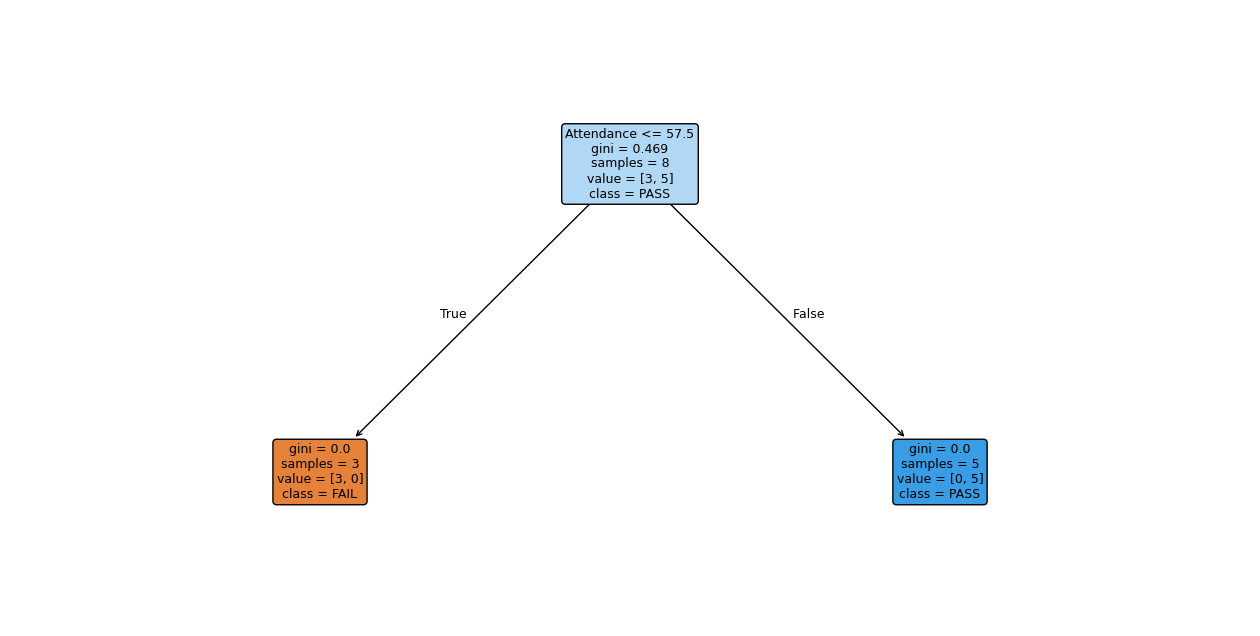

In [30]:
plt.figure(figsize=(16,8))
plot_tree(
    tree_clf,
    feature_names=x.columns,
    class_names=[str(c) for c in tree_clf.classes_],
    filled= True,
    rounded = True,
    fontsize=9

)

In [31]:
importance = pd.Series(
    tree_clf.feature_importances_,
    index=x.columns
)
importance.sort_values(
    ascending=False,
    inplace=True
)